# Credit Risk Scorecard

A probability of default (PD) scorecard built on the German Credit data, validated the way a model risk team would, then extended with two things South African lenders actually deal with: an NCR style affordability check and IFRS 9 expected credit loss.

The reusable code lives in `src/`. This notebook walks through it in order.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_data, split_data, TARGET, EXCLUDED
from src.woe import bin_features, iv_summary, apply_woe, IV_MIN, IV_SUSPICIOUS
from src.model import fit_with_sign_check, coef_table, predict_pd
from src.scorecard import build_scorecard, score_woe, scaling
from src.metrics import summary, psi, psi_table, calibration_table
from src import plots
from src.affordability import Applicant, assess, min_expense_norm
from src.ecl import ecl, lifetime_pd

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
FIG = "../reports/figures/"

## 1. Data

1 000 loans, 30% bad. Two columns are dropped before anything else:

- `personal_status_and_sex` mixes marital status with sex.
- `foreign_worker` is a proxy for nationality.

Both are protected characteristics, and using them would be unfair and, in most jurisdictions including South Africa, unlawful in a credit decision. They are removed up front so they cannot leak into binning or feature selection.

In [2]:
df = load_data()
print(df.shape, "| excluded:", EXCLUDED)
print("bad rate:", df[TARGET].mean())
df.head()

(1000, 19) | excluded: ['personal_status_and_sex', 'foreign_worker']
bad rate: 0.3


,status_of_existing_checking_account,duration_in_month,credit_history,purpose,credit_amount,savings_account_and_bonds,present_employment_since,installment_rate_in_percentage_of_disposable_income,other_debtors_or_guarantors,present_residence_since,property,age_in_years,other_installment_plans,housing,number_of_existing_credits_at_this_bank,job,number_of_people_being_liable_to_provide_maintenance_for,telephone,creditability
0,... < 0 DM,6,critical account/ other credits existing (not at this bank),radio/television,1169,unknown/ no savings account,... >= 7 years,4,none,4,real estate,67,none,own,2,skilled employee / official,1,"yes, registered under the customers name",0
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,radio/television,5951,... < 100 DM,1 <= ... < 4 years,2,none,2,real estate,22,none,own,1,skilled employee / official,1,none,1
2,no checking account,12,critical account/ other credits existing (not at this bank),education,2096,... < 100 DM,4 <= ... < 7 years,2,none,3,real estate,49,none,own,1,unskilled - resident,2,none,0
3,... < 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,... < 100 DM,4 <= ... < 7 years,2,guarantor,4,building society savings agreement/ life insurance,45,none,for free,1,skilled employee / official,2,none,0
4,... < 0 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,none,4,unknown / no property,53,none,for free,2,skilled employee / official,2,none,1


## 2. Train/test split

Stratified 70/30 with seed 42, so both sides keep the same bad rate.

In [3]:
train, test = split_data(df)
pd.DataFrame({"rows": [len(train), len(test)],
              "bad_rate": [train[TARGET].mean(), test[TARGET].mean()]},
             index=["train", "test"])

,rows,bad_rate
train,700,0.3
test,300,0.3


## 3. WoE binning and information value

Bins are fitted on train only. Features with IV below 0.02 are dropped as too weak. Anything above 0.5 is flagged: an IV that high can mean a genuinely strong driver, or a leak from the outcome, so it deserves a closer look.

In [4]:
bins = bin_features(train, TARGET)
iv = iv_summary(bins)
iv.round(4)

,feature,iv,keep,flag_high
0,status_of_existing_checking_account,0.6235,True,True
1,duration_in_month,0.2591,True,False
2,credit_history,0.2542,True,False
3,savings_account_and_bonds,0.2317,True,False
4,credit_amount,0.2011,True,False
5,age_in_years,0.1416,True,False
6,property,0.1402,True,False
7,purpose,0.1304,True,False
8,present_employment_since,0.1302,True,False
9,other_installment_plans,0.1169,True,False


In [5]:
flagged = iv.loc[iv.flag_high, "feature"].tolist()
features = iv.loc[iv.keep, "feature"].tolist()
print("kept:", len(features), "| dropped:", len(iv) - len(features), "| flagged:", flagged)
bins[flagged[0]][["bin", "count", "badprob", "woe", "bin_iv"]].round(3)

kept: 12 | dropped: 6 | flagged: ['status_of_existing_checking_account']


,bin,count,badprob,woe,bin_iv
0,... < 0 DM,192,0.479,0.764,0.179
1,"0 <= ... < 200 DM%,%... >= 200 DM / salary assignments f...",232,0.371,0.318,0.035
2,no checking account,276,0.116,-1.184,0.409


`status_of_existing_checking_account` is the flagged one. Looking at the bins, the bad rate falls steadily from overdrawn accounts to having no checking account with the bank. That is a plausible, well known driver rather than a leak, and it is information the bank has before the loan is granted, so it stays in. In production I would confirm the account status is taken at application date and not updated afterwards.

## 4. Logistic regression on WoE

WoE is defined as ln(%bad / %good), so a riskier bin has a higher WoE. Every coefficient should therefore be positive. `fit_with_sign_check` refits and drops the worst offender if any sign comes out negative.

In [6]:
X_train = apply_woe(train, bins, features)
X_test = apply_woe(test, bins, features)

model, dropped = fit_with_sign_check(X_train, train[TARGET])
cols = list(model.params.index[1:])
print("dropped for wrong sign:", dropped or "none")
coef_table(model).round(3)

dropped for wrong sign: none


,coef,std_err,p_value,sign_ok
const,-0.867,0.102,0.000,True
status_of_existing_checking_account_woe,0.785,0.136,0.000,True
duration_in_month_woe,0.743,0.215,0.001,True
credit_history_woe,0.621,0.204,0.002,True
savings_account_and_bonds_woe,0.820,0.228,0.000,True
credit_amount_woe,1.032,0.227,0.000,True
age_in_years_woe,0.761,0.279,0.006,True
property_woe,0.269,0.308,0.382,True
purpose_woe,1.043,0.281,0.000,True
present_employment_since_woe,0.685,0.277,0.013,True


All signs are positive, so every feature pushes PD in the direction its WoE says it should. Two features, `property` and `housing`, have p values above 0.05. With only 700 training rows that is expected, and they are kept because their IV clears the threshold and their signs make sense, but they are the first candidates to drop if a simpler card is needed.

## 5. Scorecard points

Base score 600 at good:bad odds of 50:1, and 20 points to double the odds (PDO 20).

Points for a bin = -factor x coefficient x WoE, with factor = 20 / ln 2. The intercept is folded into the base points.

In [7]:
factor, offset = scaling()
print(f"factor = {factor:.3f}, offset = {offset:.2f}")
card = build_scorecard(model, bins)
card

factor = 28.854, offset = 487.12


,feature,bin,woe,points
0,base,,NaN,512
1,status_of_existing_checking_account,... < 0 DM,0.763916,-17
2,status_of_existing_checking_account,"0 <= ... < 200 DM%,%... >= 200 DM / salary assignments f...",0.318039,-7
3,status_of_existing_checking_account,no checking account,-1.184134,27
4,duration_in_month,"[-inf,8.0)",-1.368276,29
5,duration_in_month,"[8.0,16.0)",-0.339283,7
6,duration_in_month,"[16.0,34.0)",0.176130,-4
7,duration_in_month,"[34.0,48.0)",0.474623,-10
8,duration_in_month,"[48.0,inf)",0.987060,-21
9,credit_history,"no credits taken/ all credits paid back duly%,%all credi...",1.090920,-20


A quick check: total points from the card should line up with the unrounded score from the model.

In [8]:
score_train = score_woe(model, X_train)
score_test = score_woe(model, X_test)
pd_train = predict_pd(model, X_train[cols])
pd_test = predict_pd(model, X_test[cols])
pd.Series(score_test).describe().round(1)

count    300.0
mean     523.1
std       44.3
min      400.9
25%      492.2
50%      525.5
75%      551.9
max      633.9
dtype: float64

## 6. Discrimination

In [9]:
results = pd.DataFrame({"Train": summary(train[TARGET], pd_train),
                        "Test": summary(test[TARGET], pd_test)}).T
results.round(3)

,AUC,Gini,KS
Train,0.835,0.669,0.537
Test,0.799,0.597,0.511


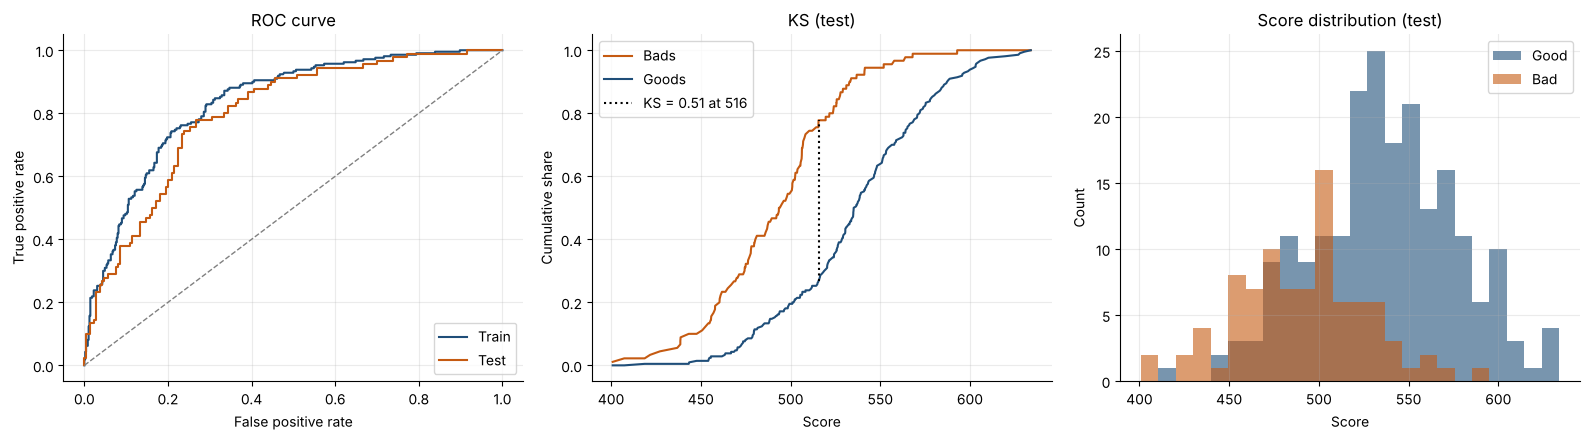

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
plots.roc_plot(train[TARGET], pd_train, test[TARGET], pd_test, ax=ax[0])
plots.ks_plot(test[TARGET], score_test, ax=ax[1])
plots.score_dist_plot(score_test, test[TARGET], ax=ax[2])
plt.tight_layout()
plt.show()

for f, name in [(plots.roc_plot, "roc.png")]:
    a = f(train[TARGET], pd_train, test[TARGET], pd_test)
    a.figure.savefig(FIG + name, dpi=150, bbox_inches="tight"); plt.close(a.figure)
a = plots.ks_plot(test[TARGET], score_test, title="KS (test)")
a.figure.savefig(FIG + "ks.png", dpi=150, bbox_inches="tight"); plt.close(a.figure)
a = plots.score_dist_plot(score_test, test[TARGET])
a.figure.savefig(FIG + "score_distribution.png", dpi=150, bbox_inches="tight"); plt.close(a.figure)

Most scores sit below 600 because the base odds of 50:1 are much better than this sample, where roughly 1 in 3 loans went bad.

Test Gini of about 0.60 is in the range you would expect for an application scorecard. Train is a bit higher, which is normal; a gap this size on 300 test rows does not point to serious overfitting.

## 7. Stability (PSI)

Train scores are the baseline. Below 0.1 is stable, 0.1 to 0.25 needs watching, above 0.25 means the population has shifted.

In [11]:
print(f"PSI train vs test: {psi(score_train, score_test):.4f}")
psi_table(score_train, score_test).round(4)

PSI train vs test: 0.0615


,bin,expected_pct,actual_pct,psi
0,-inf to 463,0.1,0.0900,0.0011
1,463 to 483,0.1,0.1167,0.0026
2,483 to 495,0.1,0.0633,0.0167
3,495 to 510,0.1,0.1167,0.0026
4,510 to 521,0.1,0.0800,0.0045
5,521 to 535,0.1,0.1533,0.0228
6,535 to 551,0.1,0.1133,0.0017
7,551 to 565,0.1,0.0833,0.0030
8,565 to 587,0.1,0.1067,0.0004
9,587 to inf,0.1,0.0767,0.0062


Both samples come from the same 1 000 loans, so a low PSI is expected here. The real use of PSI is monitoring: comparing new applicants against this baseline every month after go live.

## 8. Calibration

Predicted vs actual bad rate by score decile on test. Decile 1 is the lowest scores, i.e. the riskiest.

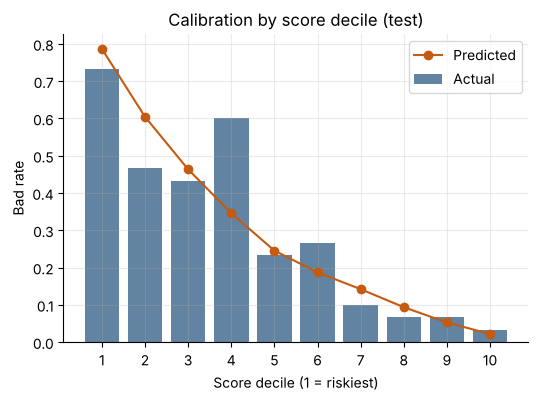

,decile,min_score,max_score,count,predicted_bad_rate,actual_bad_rate
0,1,400.894,464.984,30,0.787,0.733
1,2,466.811,480.404,30,0.604,0.467
2,3,481.227,499.379,30,0.464,0.433
3,4,500.728,512.051,30,0.346,0.600
4,5,514.287,525.488,30,0.245,0.233
5,6,525.538,534.216,30,0.187,0.267
6,7,534.839,546.281,30,0.142,0.100
7,8,546.538,562.914,30,0.094,0.067
8,9,562.939,580.833,30,0.053,0.067
9,10,582.036,633.873,30,0.022,0.033


In [12]:
cal = calibration_table(test[TARGET], pd_test, score_test)
a = plots.calibration_plot(cal)
a.figure.savefig(FIG + "calibration.png", dpi=150, bbox_inches="tight")
plt.show()
cal.round(3)

In [13]:
print(f"mean predicted PD: {pd_test.mean():.3f}  |  actual bad rate: {test[TARGET].mean():.3f}")

mean predicted PD: 0.294  |  actual bad rate: 0.300


The model ranks well and the overall level is right (mean predicted PD 0.294 vs actual 0.300). Decile 4 is the exception: 18 bads out of 30 against about 10 predicted. With 30 loans per decile the standard error is around 0.09, so that is roughly three standard errors out. One decile like that among ten can happen by chance, and the deciles either side of it are fine, so I read it as sample noise rather than a fault in the model, but it is the first thing I would check again on a larger sample.

Note the 30% bad rate is far higher than a real loan book. The dataset was oversampled for bads, so before using these PDs for pricing or provisioning they would need recalibrating to the true portfolio default rate.

## 9. South African layer: affordability

Under the National Credit Act, a lender has to do an affordability assessment, not just a risk score. The NCR regulations set minimum monthly living expenses by gross income band, and the lender has to use the higher of these and what the applicant declares.

The German data has no rand income, so the applicants below are made up to show the decision logic. Rule: approve only if the score clears the cutoff **and** the new instalment fits in discretionary income.

In [14]:
pd.DataFrame({"gross_income": [5000, 15000, 30000, 60000]}).assign(
    min_expense_norm=lambda d: d.gross_income.map(min_expense_norm).round(2))

,gross_income,min_expense_norm
0,5000,1083.50
1,15000,1955.38
2,30000,3265.38
3,60000,5580.38


In [15]:
cutoff = 520
applicants = [
    ("Thandi", Applicant(18000, 14500, 4000, 2500), 565, 40000, 0.21, 36),
    ("Sipho", Applicant(18000, 14500, 4000, 2500), 495, 40000, 0.21, 36),
    ("Lerato", Applicant(12000, 10200, 5500, 3200), 575, 60000, 0.24, 48),
    ("Pieter", Applicant(45000, 33000, 12000, 9000), 600, 150000, 0.16, 60),
]
rows = []
for name, a, score, amount, rate, months in applicants:
    r = assess(a, score, amount, rate, months, cutoff=cutoff, buffer=0.1)
    rows.append({"applicant": name, "score": score, "loan": amount, **r})
pd.DataFrame(rows)

,applicant,score,loan,instalment,discretionary_income,score_ok,affordable,decision
0,Thandi,565,40000,1507.00,7200.0,True,True,approve
1,Sipho,495,40000,1507.00,7200.0,False,True,decline: score
2,Lerato,575,60000,1956.11,1350.0,True,False,decline: affordability
3,Pieter,600,150000,3647.71,10800.0,True,True,approve


Lerato passes on score but fails on affordability, which is exactly the case the regulations are there to catch. A score alone would have approved a loan the applicant cannot carry.

## 10. South African layer: IFRS 9 expected credit loss

Banks in South Africa report under IFRS 9, so the PD model feeds straight into provisions: ECL = PD x LGD x EAD.

Assumptions for this illustration:
- the model PD is treated as a 12 month PD (the German target has no fixed window, so this is a simplification),
- LGD of 45%, the Basel foundation value for senior unsecured exposure,
- EAD is the loan amount (the data is in Deutsche Mark, so read it as currency units),
- remaining term is the loan duration,
- no arrears data exists, so stage 2 is triggered on PD alone: PD at least double the portfolio average, standing in for the usual "doubled since origination" test.

In [16]:
LGD = 0.45
book = test[["credit_amount", "duration_in_month"]].copy()
book["pd_12m"] = pd_test
avg_pd = book["pd_12m"].mean()
book["stage"] = np.where(book["pd_12m"] >= 2 * avg_pd, 2, 1)
book["years"] = book["duration_in_month"] / 12
book["ecl"] = [
    ecl(p, LGD, ead, stage=s, remaining_years=y, eir=0.12)
    for p, ead, s, y in zip(book.pd_12m, book.credit_amount, book.stage, book.years)
]

by_stage = book.groupby("stage").agg(loans=("ecl", "size"),
                                    exposure=("credit_amount", "sum"),
                                    ecl=("ecl", "sum"))
by_stage["coverage"] = by_stage["ecl"] / by_stage["exposure"]
by_stage.loc["total"] = [by_stage.loans.sum(), by_stage.exposure.sum(),
                         by_stage.ecl.sum(), by_stage.ecl.sum() / by_stage.exposure.sum()]
by_stage.round(3)

,loans,exposure,ecl,coverage
stage,,,,
1,252.0,784991.0,77835.975,0.099
2,48.0,245656.0,91772.734,0.374
total,300.0,1030647.0,169608.708,0.165


Stage 2 loans carry lifetime ECL, so their coverage is several times higher than stage 1. That jump is why the staging rule matters as much as the PD model itself: moving a loan from stage 1 to stage 2 can multiply its provision.

Again the coverage numbers are inflated by the 30% bad rate. After recalibrating to a real default rate they would come down a lot.

## 11. Summary

- 12 features kept after IV filtering, all with sensible coefficient signs.
- Test AUC about 0.80, Gini about 0.60, KS about 0.51.
- PSI between train and test is low, so the score is stable across the split.
- Calibration is reasonable in rank and level, but the PDs reflect an oversampled 30% bad rate.

Full write up, including limitations, is in `reports/validation.md`.